# 04 · Red neuronal y comparación final

**Objetivo:** entrenar una red neuronal con las mismas filas y variables que LightGBM, y comparar todos los modelos del proyecto, con intervalos de confianza que indiquen si las diferencias son reales o están dentro del ruido.

**Referencias a superar** (notebooks 02 y 03): SES + índice semanal tiene RMSSE de 0,742 (validación) y 0,769 (test); LightGBM, 0,740 y 0,768. Es prácticamente un empate.

**Diseño de la red:**
- **Misma estrategia directa que LightGBM:** cada fila es una serie, un origen y un día del horizonte, con las mismas variables, para que la única diferencia sea el modelo.
- **Variables numéricas:** las muy sesgadas (ventas y promedios) se transforman con `log(1 + x)`, y todas se estandarizan. Los valores faltantes se completan y se agrega un indicador de faltante.
- **Variables categóricas con embeddings:** tienda, departamento, categoría, tipo de evento y día de la semana. Un *embedding* es una representación numérica de cada categoría, de pocas dimensiones, que la red aprende durante el entrenamiento.
- **Perceptrón multicapa:** tres capas ocultas (256, 128 y 64 unidades) con dropout de 0,1, y una salida positiva (activación `softplus`), porque las ventas no pueden ser negativas.
- **Función de pérdida:** de la familia de Tweedie, como en LightGBM. Se comparan la pérdida de Poisson (exponente 1) y la de Tweedie con exponente 1,5, que fue el mejor en LightGBM.
- **Varias redes con distintas semillas:** el entrenamiento de una red depende del azar (inicialización y orden de los datos). Se entrenan 3 redes con semillas distintas y se promedian sus pronósticos, lo que reduce esa variabilidad.

**Protocolo:** el del notebook 01, igual que con LightGBM. Se elige la pérdida en validación (con el mismo conjunto de control para la parada temprana) y se reentrena con datos hasta el origen del test, que se evalúa una sola vez.

## 1. Setup y datos

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import ensure_m5, load_calendar, load_prices, load_sales, day_columns, sample_series, SEED
from src.metrics import evaluar
from src.forecasting import (
    ventanas, guardar_resultados, pronostico_cero, pronostico_ingenuo,
    pronostico_ingenuo_estacional, pronostico_media_movil,
    pronostico_promedio_estacional, ses_semanal,
)
from src.gbm import HORIZONTE, preparar_contexto, construir_dataset, construir_varios, a_matriz
from src.nn import Preprocesador, entrenar_red, reentrenar_red
from src.comparacion import por_serie, bootstrap_pareado

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)
print("TensorFlow/Keras:", keras.__version__)

TensorFlow/Keras: 3.15.1


In [2]:
carpeta = ensure_m5()
calendario = load_calendar(carpeta)
precios = load_prices(carpeta)
ventas = load_sales(carpeta)
dias = day_columns(ventas)

muestra = sample_series(ventas, n_per_store=60, seed=SEED)
ctx = preparar_contexto(muestra, calendario, precios, dias)

Y = ctx["Y"]
n, T = Y.shape
H = HORIZONTE
V = ventanas(T, H)
o_val = V["validación"][0] - 1
o_test = V["test"][0] - 1
Y_train_val, Y_real_val = Y[:, :o_val], Y[:, o_val:o_val + H]
Y_train_test, Y_real_test = Y[:, :o_test], Y[:, o_test:o_test + H]
print(f"Series: {n} | días: {T} | origen de validación: {o_val} | origen de test: {o_test}")

Series: 600 | días: 1941 | origen de validación: 1885 | origen de test: 1913


## 2. Conjuntos de entrenamiento

Son los mismos del notebook 03: orígenes semanales que caen el mismo día de la semana que el origen a evaluar, los últimos `N_ORIGENES` (52 equivalen a un año), con los 4 más recientes reservados como conjunto de control para la parada temprana (dejar de entrenar cuando el error de control deja de mejorar).

In [3]:
N_ORIGENES = 52
PASO = 7
N_CONTROL = 4
N_SEMILLAS = 3     # redes entrenadas con semillas distintas, cuyos pronósticos se promedian
EPOCAS_MAX = 30
BATCH = 1024

orig_val = [o_val - H - PASO * j for j in range(N_ORIGENES)]
orig_test = [o_test - H - PASO * j for j in range(N_ORIGENES)]

t0 = time.time()
X_ctrl, y_ctrl = construir_varios(ctx, orig_val[:N_CONTROL])
X_tr, y_tr = construir_varios(ctx, orig_val[N_CONTROL:])

prep = Preprocesador().fit(X_tr)
ent_tr, ent_ctrl = prep.transform(X_tr), prep.transform(X_ctrl)
print(f"Entrenamiento: {len(X_tr):,} filas | control: {len(X_ctrl):,} filas | {time.time() - t0:.0f} s")
print(f"Entradas numéricas: {len(prep.columnas)} | categorías por embedding: {prep.n_cat}")

Entrenamiento: 800,212 filas | control: 67,172 filas | 3 s
Entradas numéricas: 33 | categorías por embedding: {'tienda': 10, 'departamento': 7, 'categoria': 3, 'tipo_evento': 5, 'dia_semana': 7}


## 3. Elección de la pérdida (en validación)

Se entrenan 3 redes por cada pérdida y se promedian. Se reporta el RMSSE y el MAE del promedio en la ventana de validación, y el RMSSE de las redes individuales (mínimo y máximo), para ver cuánto varía el resultado según la semilla. El criterio de elección es el RMSSE del promedio.

In [4]:
def predecir_redes(modelos, prep_, origen):
    X, _, idx = construir_dataset(ctx, origen, con_objetivo=False)
    ent = prep_.transform(X)
    individuales = [a_matriz(m.predict(ent, batch_size=4096, verbose=0).ravel(), idx, n) for m in modelos]
    return np.mean(individuales, axis=0), individuales

PERDIDAS = {"Poisson": 1.0, "Tweedie 1,5": 1.5}
resumen, redes_val, preds_val, mejores_epocas, historiales = [], {}, {}, {}, {}

for nombre, p in PERDIDAS.items():
    t0 = time.time()
    modelos, epocas = [], []
    for s in range(N_SEMILLAS):
        m, mejor_ep, hist = entrenar_red(prep, ent_tr, y_tr, ent_ctrl, y_ctrl, p,
                                         semilla=SEED + s, epocas=EPOCAS_MAX, batch=BATCH)
        modelos.append(m)
        epocas.append(mejor_ep)
        if s == 0:
            historiales[nombre] = hist
    pred, individuales = predecir_redes(modelos, prep, o_val)
    m_prom = evaluar(Y_train_val, Y_real_val, pred)
    r_ind = [evaluar(Y_train_val, Y_real_val, pi)["RMSSE"] for pi in individuales]
    redes_val[nombre], preds_val[nombre], mejores_epocas[nombre] = modelos, pred, epocas
    fila = {"pérdida": nombre, "épocas": float(np.mean(epocas)), "RMSSE (promedio de redes)": m_prom["RMSSE"],
            "MAE (promedio de redes)": m_prom["MAE"], "RMSSE red mín.": min(r_ind), "RMSSE red máx.": max(r_ind),
            "minutos": (time.time() - t0) / 60}
    resumen.append(fila)
    print(f"{nombre:<12} épocas {fila['épocas']:.1f} | RMSSE {fila['RMSSE (promedio de redes)']:.3f} | "
          f"MAE {fila['MAE (promedio de redes)']:.3f} | redes individuales {min(r_ind):.3f}-{max(r_ind):.3f} | {fila['minutos']:.1f} min")

Poisson      épocas 7.7 | RMSSE 0.751 | MAE 1.013 | redes individuales 0.752-0.757 | 1.5 min
Tweedie 1,5  épocas 5.7 | RMSSE 0.749 | MAE 1.015 | redes individuales 0.746-0.755 | 1.3 min


In [5]:
tabla_nn = pd.DataFrame(resumen).set_index("pérdida")
mejor = tabla_nn["RMSSE (promedio de redes)"].idxmin()
print("Pérdida elegida (menor RMSSE en validación):", mejor)
tabla_nn.round(3)

Pérdida elegida (menor RMSSE en validación): Tweedie 1,5


,épocas,RMSSE (promedio de redes),MAE (promedio de redes),RMSSE red mín.,RMSSE red máx.,minutos
pérdida,,,,,,
Poisson,7.667,0.751,1.013,0.752,0.757,1.547
"Tweedie 1,5",5.667,0.749,1.015,0.746,0.755,1.291


**Lectura.** Los dos exponentes difieren en 0,002: en RMSSE a favor de Tweedie 1,5 (0,749 contra 0,751) y en MAE a favor de Poisson (1,013 contra 1,015). El rango de RMSSE entre las redes individuales de cada pérdida (0,746 a 0,755 y 0,752 a 0,757) es mayor que esa diferencia, por lo que elegir entre las dos pérdidas es en la práctica un desempate. El criterio fijado de antemano (RMSSE del promedio de las redes) selecciona Tweedie 1,5.

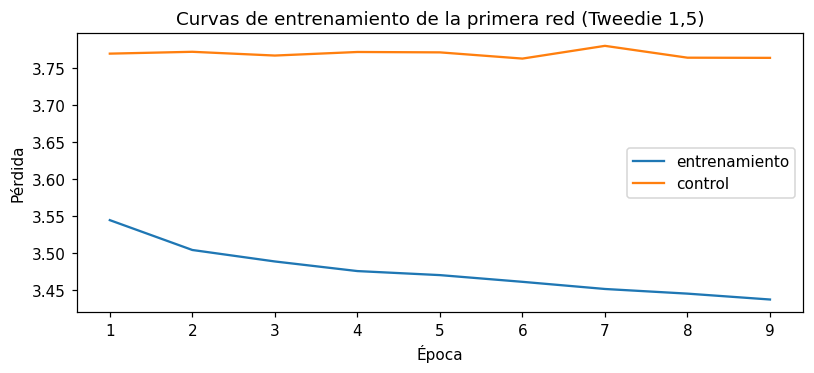

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.5))
h = historiales[mejor]
ax.plot(np.arange(1, len(h["loss"]) + 1), h["loss"], label="entrenamiento")
ax.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], label="control")
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida")
ax.set_title(f"Curvas de entrenamiento de la primera red ({mejor})")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Modelo final y evaluación en test

Con la pérdida elegida y el número de épocas promedio que decidió la parada temprana en validación, se reentrenan 3 redes con los orígenes hasta `o_test − 28` (que incluyen los datos de la ventana de validación), sin conjunto de control. Se evalúa en test **una sola vez**.

In [7]:
p_final = PERDIDAS[mejor]
epocas_final = max(1, int(round(np.mean(mejores_epocas[mejor]))))

t0 = time.time()
X_fin, y_fin = construir_varios(ctx, orig_test)
prep_fin = Preprocesador().fit(X_fin)
ent_fin = prep_fin.transform(X_fin)

redes_finales = [reentrenar_red(prep_fin, ent_fin, y_fin, p_final, epocas_final, semilla=SEED + s, batch=BATCH)
                 for s in range(N_SEMILLAS)]
pred_nn_test, ind_test = predecir_redes(redes_finales, prep_fin, o_test)
print(f"Reentrenadas {N_SEMILLAS} redes con {len(X_fin):,} filas y {epocas_final} épocas en {(time.time() - t0) / 60:.1f} min")

m_val = evaluar(Y_train_val, Y_real_val, preds_val[mejor])
m_test = evaluar(Y_train_test, Y_real_test, pred_nn_test)
print(f"Validación -> RMSSE {m_val['RMSSE']:.3f} | MAE {m_val['MAE']:.3f}")
print(f"Test       -> RMSSE {m_test['RMSSE']:.3f} | MAE {m_test['MAE']:.3f}")

Reentrenadas 3 redes con 868,588 filas y 6 épocas en 1.0 min
Validación -> RMSSE 0.749 | MAE 1.015
Test       -> RMSSE 0.772 | MAE 1.023


## 5. Comparación de todos los modelos

Se reúnen los pronósticos de todos los modelos en las dos ventanas: los baselines y SES (se recalculan, porque son deterministas), LightGBM (se leen de `reports/predicciones_lightgbm.npz`) y la red neuronal. Además se agrega una **combinación 50/50 de LightGBM y la red neuronal**, una regla fija definida de antemano, no ajustada a los resultados.

In [8]:
wday = calendario["wday"].to_numpy() - 1
categorias = muestra["cat_id"].astype(str).to_numpy()
origenes = {"validación": o_val, "test": o_test}
Y_tr = {"validación": Y_train_val, "test": Y_train_test}
Y_re = {"validación": Y_real_val, "test": Y_real_test}

lgbm = np.load(os.path.join(ROOT, "reports", "predicciones_lightgbm.npz"))
assert (lgbm["ids"] == muestra["id"].astype(str).to_numpy().astype("U")).all(), "El orden de las series no coincide con el del notebook 03"

todas = {}
for v, o in origenes.items():
    Yh = Y_tr[v]
    todas[("Cero", v)] = pronostico_cero(Yh, H)
    todas[("Ingenuo", v)] = pronostico_ingenuo(Yh, H)
    todas[("Ingenuo estacional", v)] = pronostico_ingenuo_estacional(Yh, H)
    todas[("Media móvil 28 días", v)] = pronostico_media_movil(Yh, H)
    todas[("Promedio estacional (4 semanas)", v)] = pronostico_promedio_estacional(Yh, H)
    todas[("SES + índice semanal", v)] = ses_semanal(Yh, H, wday[:o], wday[o:o + H], categorias)[0]
    todas[("LightGBM", v)] = lgbm["validacion" if v == "validación" else "test"]
todas[("Red neuronal", "validación")] = preds_val[mejor]
todas[("Red neuronal", "test")] = pred_nn_test
for v in origenes:
    todas[("Promedio LightGBM + red neuronal", v)] = 0.5 * (todas[("LightGBM", v)] + todas[("Red neuronal", v)])

modelos_lista = list(dict.fromkeys(m for m, _ in todas))
filas = [{"modelo": m, "ventana": v, **evaluar(Y_tr[v], Y_re[v], todas[(m, v)])} for (m, v) in todas]
resultados = pd.DataFrame(filas)

tabla = resultados.pivot(index="modelo", columns="ventana", values=["RMSSE", "MAE"])
tabla = tabla[[("RMSSE", "validación"), ("RMSSE", "test"), ("MAE", "validación"), ("MAE", "test")]]
tabla.sort_values(("RMSSE", "test")).round(3)

RMSSE               MAE       
ventana                          validación   test validación   test
modelo                                                              
LightGBM                              0.740  0.768      0.983  1.011
Promedio LightGBM + red neuronal      0.743  0.769      0.994  1.013
SES + índice semanal                  0.742  0.769      1.036  1.008
Red neuronal                          0.749  0.772      1.015  1.023
Media móvil 28 días                   0.751  0.782      1.020  1.059
Promedio estacional (4 semanas)       0.811  0.849      1.045  1.101
Cero                                  0.940  0.990      1.392  1.477
Ingenuo                               0.936  1.007      1.361  1.306
Ingenuo estacional                    0.995  1.029      1.195  1.233

**Lectura.** Con tres decimales hay empates: LightGBM tiene el menor RMSSE en test (0,768), seguido por la combinación 50/50 y SES (0,769 ambos), y SES tiene el menor MAE (1,008). Los cuatro mejores modelos quedan dentro de un 0,5 % en RMSSE; la sección siguiente evalúa si esas diferencias superan el ruido entre series.

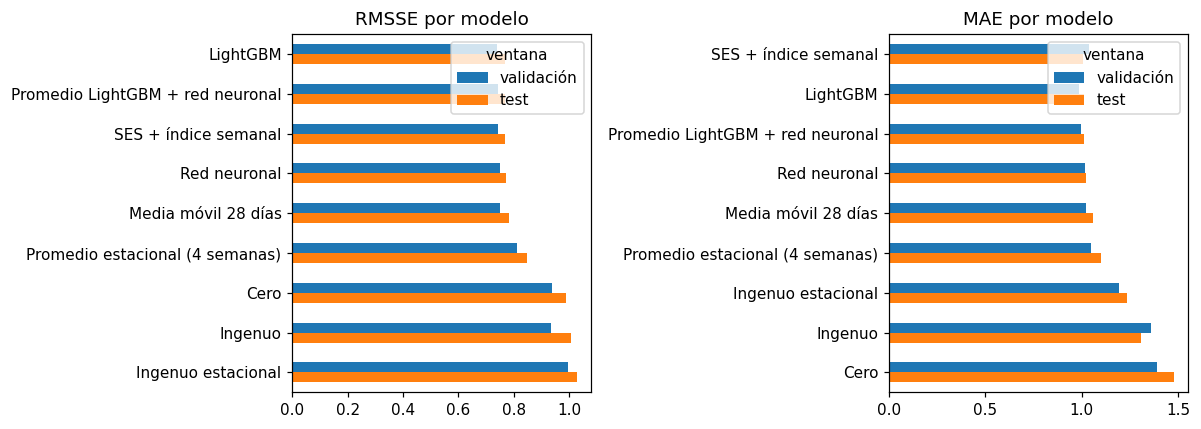

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metrica in zip(axes, ["RMSSE", "MAE"]):
    tabla[metrica].sort_values("test").plot.barh(ax=ax)
    ax.set_title(metrica + " por modelo")
    ax.set_ylabel("")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 5.1 ¿Las diferencias son reales? Bootstrap entre series

Los modelos de arriba difieren en centésimas. Para saber si esas diferencias son mayores que el ruido, se calcula el error de cada serie con cada modelo y se compara de a pares con un **bootstrap pareado**: se remuestrean las 600 series con reemplazo (5.000 veces), conservando el emparejamiento entre modelos, y se obtiene un intervalo de confianza del 95 % de la diferencia media de error. Una diferencia **negativa** significa que el primer modelo se equivoca menos; `prob_A_mejor` es la proporción de remuestras en que el primer modelo tiene menor error.

**Qué incluye y qué no:** el bootstrap mide la variabilidad debida a *qué series* se eligieron, pero no la debida a *qué ventana de tiempo* se evaluó: hay una sola ventana por etapa, y otra ventana podría dar un resultado distinto.

In [10]:
rng = np.random.default_rng(SEED)
serie = {(m, v): por_serie(Y_tr[v], Y_re[v], todas[(m, v)]) for (m, v) in todas}

PARES = [
    ("LightGBM", "SES + índice semanal"),
    ("Red neuronal", "SES + índice semanal"),
    ("Red neuronal", "LightGBM"),
    ("Promedio LightGBM + red neuronal", "SES + índice semanal"),
    ("SES + índice semanal", "Media móvil 28 días"),
]

filas = []
for A, B in PARES:
    for v in origenes:
        for k, metrica in enumerate(["RMSSE", "MAE"]):
            r = bootstrap_pareado(serie[(A, v)][k], serie[(B, v)][k], n_boot=5000, rng=rng)
            filas.append({"comparación (A − B)": f"{A} − {B}", "ventana": v, "métrica": metrica,
                          "dif": r["dif"], "ic_bajo": r["ic_bajo"], "ic_alto": r["ic_alto"], "prob_A_mejor": r["prob_a_mejor"]})
boot = pd.DataFrame(filas)
boot["IC excluye 0"] = (boot["ic_bajo"] > 0) | (boot["ic_alto"] < 0)
boot.round(4)

,comparación (A − B),ventana,métrica,dif,ic_bajo,ic_alto,prob_A_mejor,IC excluye 0
0,LightGBM − SES + índice semanal,validación,RMSSE,-0.0018,-0.0079,0.0046,0.7180,False
1,LightGBM − SES + índice semanal,validación,MAE,-0.0527,-0.1164,-0.0051,0.9872,True
2,LightGBM − SES + índice semanal,test,RMSSE,-0.0009,-0.0056,0.0039,0.6546,False
3,LightGBM − SES + índice semanal,test,MAE,0.0035,-0.0120,0.0196,0.3238,False
4,Red neuronal − SES + índice semanal,validación,RMSSE,0.0076,-0.0012,0.0183,0.0466,False
5,Red neuronal − SES + índice semanal,validación,MAE,-0.0211,-0.0823,0.0296,0.7836,False
6,Red neuronal − SES + índice semanal,test,RMSSE,0.0029,-0.0019,0.0080,0.1254,False
7,Red neuronal − SES + índice semanal,test,MAE,0.0150,-0.0042,0.0391,0.0716,False
8,Red neuronal − LightGBM,validación,RMSSE,0.0093,0.0037,0.0158,0.0002,True
9,Red neuronal − LightGBM,validación,MAE,0.0316,0.0115,0.0554,0.0000,True


**Lectura.** De las 20 comparaciones, 6 tienen un intervalo que excluye el cero: red neuronal − LightGBM en validación (RMSSE y MAE), SES − media móvil en RMSSE (en las dos ventanas) y en MAE de test, y LightGBM − SES en MAE de validación. Con 20 intervalos del 95 % cabe esperar, aproximadamente, uno que excluya el cero por azar aunque no hubiera diferencias reales, y no se corrigió por comparaciones múltiples: las diferencias que se repiten en varias métricas o ventanas son más confiables que las que aparecen aisladas.

**Cuánto ruido hay.** Los intervalos del RMSSE tienen un semiancho de 0,004 a 0,010 (entre 0,5 % y 1,3 % del valor del RMSSE), así que, respecto de la variabilidad entre series, diferencias de menos de alrededor de 1 % no se distinguen del ruido; es lo que anticipaba el notebook 03. Los intervalos del MAE son mucho más anchos en términos relativos: en LightGBM − SES en validación, el ancho es de 0,012 en RMSSE (1,7 % del RMSSE de SES) y de 0,111 en MAE (11 % del MAE de SES). En red neuronal − LightGBM en test, el intervalo del RMSSE (−0,0004 a 0,0088) casi excluye el cero y la probabilidad de que la red sea mejor es del 4 %.

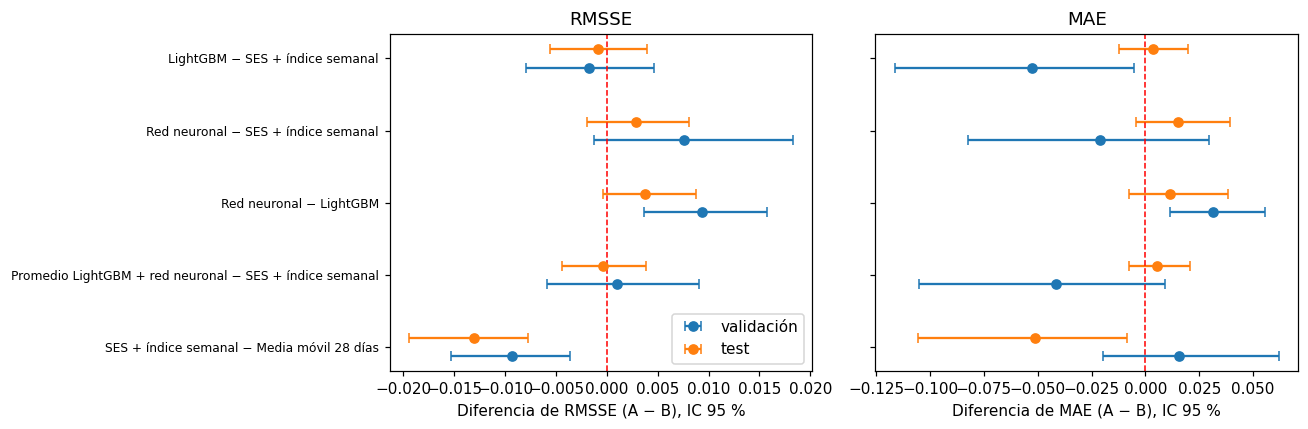

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
etiquetas = [f"{A} − {B}" for A, B in PARES]
for ax, metrica in zip(axes, ["RMSSE", "MAE"]):
    for k, (v, color) in enumerate([("validación", "tab:blue"), ("test", "tab:orange")]):
        t = boot[(boot["métrica"] == metrica) & (boot["ventana"] == v)].set_index("comparación (A − B)").loc[etiquetas]
        y = np.arange(len(t))[::-1] + (k - 0.5) * 0.25
        ax.errorbar(t["dif"], y, xerr=[t["dif"] - t["ic_bajo"], t["ic_alto"] - t["dif"]], fmt="o", capsize=3, color=color, label=v)
    ax.axvline(0, color="red", linestyle="--", linewidth=1)
    ax.set_yticks(np.arange(len(etiquetas))[::-1])
    ax.set_yticklabels(etiquetas, fontsize=8)
    ax.set_xlabel(f"Diferencia de {metrica} (A − B), IC 95 %")
    ax.set_title(metrica)
axes[0].legend()
plt.tight_layout()
plt.show()

## 6. Guardar resultados

In [12]:
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)
nuevos = resultados[resultados["modelo"].isin(["Red neuronal", "Promedio LightGBM + red neuronal"])]
acumulado = guardar_resultados(nuevos, os.path.join(ROOT, "reports", "resultados_modelos.csv"))
resultados.to_csv(os.path.join(ROOT, "reports", "comparacion_final.csv"), index=False)
boot.to_csv(os.path.join(ROOT, "reports", "comparacion_bootstrap.csv"), index=False)
tabla_nn.to_csv(os.path.join(ROOT, "reports", "red_neuronal_experimentos.csv"))
np.savez(os.path.join(ROOT, "reports", "predicciones_red_neuronal.npz"),
         validacion=preds_val[mejor], test=pred_nn_test, ids=muestra["id"].astype(str).to_numpy().astype("U"))
print("Resultados guardados en reports/")

Resultados guardados en reports/


## 7. Conclusiones

- **Elección de la pérdida:** Poisson y Tweedie 1,5 dan un RMSSE de 0,751 y 0,749 y un MAE de 1,013 y 1,015 en validación. La diferencia (0,002) es menor que la variación entre semillas de una misma pérdida (RMSSE de las redes individuales entre 0,746 y 0,755 con Tweedie y entre 0,752 y 0,757 con Poisson), y en MAE el orden se invierte. La elección de Tweedie 1,5 por menor RMSSE es un desempate y no un resultado concluyente. La parada temprana eligió en promedio 6 épocas (5,7 con Tweedie y 7,7 con Poisson) de un máximo de 30, es decir, el error de control deja de mejorar pronto. Una posible explicación (hipótesis sin verificar) es que las filas de una misma serie y de orígenes cercanos están muy correlacionadas y aportan menos información independiente de la que sugieren las 868.588 filas.
- **Red neuronal (tres redes promediadas, reentrenadas con 6 épocas):** RMSSE de 0,749 en validación y 0,772 en test, y MAE de 1,015 y 1,023.
- **Comparación final en test (RMSSE; MAE):** LightGBM (0,768; 1,011), la combinación 50/50 de LightGBM y la red (0,769; 1,013), SES + índice semanal (0,769; 1,008), red neuronal (0,772; 1,023) y media móvil de 28 días (0,782; 1,059). El promedio estacional de 4 semanas (0,849) y los modelos ingenuos (1,007 y 1,029) quedan claramente por detrás. Los cuatro mejores modelos están dentro de un 0,5 % en RMSSE, y el mejor mejora en alrededor de un 24 % en RMSSE al ingenuo (1,007).
- **Qué diferencias son reales (bootstrap entre series, IC del 95 %):** de las 20 comparaciones, solo 6 tienen un intervalo que excluye el cero, y con 20 intervalos cabe esperar aproximadamente uno por azar.
  - **SES supera a la media móvil en RMSSE en las dos ventanas** (−0,0093 en validación y −0,0131 en test, un 1,2 % y un 1,7 %) y en MAE en test (−0,051; en MAE de validación la diferencia es +0,016 y el intervalo incluye el cero). Es la única diferencia que se sostiene en ambas ventanas. Esto precisa lo que se dijo en el notebook 02, donde la diferencia se midió sin intervalo y se calificó como no concluyente: respecto de la variabilidad entre series es confiable, pero sigue sin medirse la variabilidad entre ventanas de tiempo.
  - **La red neuronal rinde peor que LightGBM** en validación (RMSSE +0,0093 y MAE +0,0316, con una probabilidad de que la red sea mejor menor al 0,1 %). En test la diferencia es menor y los intervalos incluyen el cero (RMSSE +0,0038, con IC de −0,0004 a 0,0088, y probabilidad de que la red sea mejor del 4 %; MAE +0,0116), pero el signo es el mismo en las cuatro combinaciones.
  - **LightGBM no supera de forma confiable a SES.** Su ventaja de MAE en validación (−0,053, IC de −0,116 a −0,005) desaparece en test (+0,0035, con IC de −0,012 a 0,020), y en RMSSE los intervalos incluyen el cero en ambas ventanas (−0,0018 y −0,0009). Como la configuración de LightGBM se eligió entre seis en esa misma ventana de validación, su resultado allí es algo optimista.
  - **La red neuronal tampoco supera a SES:** en RMSSE la diferencia es positiva en las dos ventanas (+0,0076 y +0,0029), con intervalos que incluyen el cero, y en MAE los signos son contradictorios (−0,021 en validación y +0,015 en test), lo que indica ruido.
  - **La combinación de LightGBM y la red no aporta:** es prácticamente igual a SES en RMSSE (0,743 y 0,769; diferencias de +0,0010 y −0,0003 con intervalos que incluyen el cero) y, en las cuatro cifras de la tabla, queda levemente por detrás de LightGBM solo (0,743 contra 0,740 y 0,769 contra 0,768 en RMSSE; 0,994 contra 0,983 y 1,013 contra 1,011 en MAE), aunque esa comparación no se evaluó con bootstrap.
- **Cuánto ruido hay:** los intervalos del RMSSE tienen un semiancho de 0,004 a 0,010 (0,5 % a 1,3 % del RMSSE), por lo que, respecto de la variabilidad entre series, las diferencias de menos de alrededor de 1 % no se distinguen del ruido. Los intervalos del MAE son mucho más anchos en términos relativos (en LightGBM − SES en validación, 0,111, un 11 % del MAE de SES, contra 0,012 en RMSSE, un 1,7 % del RMSSE de SES). Una posible explicación (hipótesis sin verificar) es que el MAE está en unidades y unas pocas series de mucho volumen lo dominan, mientras que el RMSSE da el mismo peso a cada serie; es coherente con el notebook 02, donde las 45 series suaves y erráticas explicaban alrededor del 31 % del error absoluto de "Cero". En test, las diferencias puntuales de la red en MAE son positivas respecto de SES y de LightGBM (+0,015 y +0,012), pero sus intervalos incluyen el cero.
- **Variación entre semillas:** el RMSSE de las redes individuales de Tweedie varía hasta 0,009 según la semilla (0,746 a 0,755), más que la diferencia entre LightGBM y SES (0,002 en validación y 0,001 en test). Con una sola red, el resultado dependería en buena parte de la semilla; con solo 3 redes, además, el rango observado es una estimación gruesa de esa variabilidad.
- **Lectura general (hipótesis sin verificar):** a nivel de producto, tienda y día, la demanda es tan esporádica y ruidosa que casi todo lo que se puede predecir está en el nivel reciente de ventas. La estacionalidad semanal parece aportar poco a nivel de serie: en el notebook 02, SES (que usa un índice semanal) supera a la media móvil (que no lo usa) solo en 1 a 2 %, y en LightGBM el día de la semana pesa 0,7 % de la ganancia (notebook 03). Las variables adicionales (eventos, SNAP, precios, antigüedad) y los modelos más flexibles no producen una mejora confiable en estas ventanas.
- **Limitaciones:** una sola ventana por etapa (el bootstrap cubre la variabilidad entre series, pero no entre ventanas de tiempo) y sin corrección por comparaciones múltiples; 600 series de las 30.490; una ventana de validación sin eventos y un test con eventos menores; hiperparámetros de LightGBM y de la red explorados de forma limitada (arquitectura, tasa de aprendizaje y regularización de la red sin ajustar, y solo dos pérdidas probadas); una red que es un perceptrón multicapa sobre las mismas variables que LightGBM, por lo que los resultados no se extienden a arquitecturas secuenciales como LSTM o Transformers; solo 3 semillas por red; RMSSE sin ponderar por ingresos, a diferencia del WRMSSE de la competencia; y un solo origen para estimar el desempeño.
- **Trabajo futuro:** evaluar con varios orígenes consecutivos para estimar la variabilidad entre ventanas, usar las 30.490 series, ajustar mejor los hiperparámetros, probar arquitecturas secuenciales, agregar variables agregadas por tienda o producto y evaluar el WRMSSE.